# Bản đã chạy — CPU cục bộ, không phải Kaggle

Notebook này chứa outputs thực từ việc chạy toàn bộ cell bằng Jupyter kernel trên máy Windows cục bộ, Python 3.12, PyTorch CPU, ngày 18/10/2026. **Không train lại.** Tập test: 5.162 câu của `levandai1704/PAP_NER_dedup_70_15_15`.

Kernel dùng môi trường Python ở `E:/Github/papner_hsupcon_inference/.venv/` và lưu kết quả ở `E:/Github/papner_hsupcon_inference/verification/`. Các dependency đã cài nên lượt này đặt `PAPNER_SKIP_INSTALL=1`; đặt `PAPNER_FORCE_CPU=1`, `PAPNER_MAX_SENTENCES=0`, `PAPNER_BATCH_SIZE=32`. Mã inference giữ nguyên bản Kaggle.

Để chạy mới trên Kaggle, dùng `PAPNER_HSupCon_Predict_Test_Kaggle.ipynb`. Không dùng thời gian CPU ở bản này làm số đo tốc độ GPU Kaggle.

# PAP_NER: dự đoán lại bằng checkpoint PhoBERT-v2 + CRF + Hierarchical SupCon

**Chỉ inference, không train lại.** Tải checkpoint GitHub Releases `v1.0.0`,
kiểm tra SHA-256, rồi dự đoán đúng file test của
[`levandai1704/PAP_NER_dedup_70_15_15`](https://huggingface.co/datasets/levandai1704/PAP_NER_dedup_70_15_15).

**Kaggle:** Import Notebook → upload file `.ipynb` → bật **Internet** và
**GPU T4/P100** → **Run All**. Chỉ cần một GPU; notebook không khởi động train.
Không cần Kaggle Dataset đính kèm, token Hugging Face, Java hay VnCoreNLP.

Nguồn trọng số/mã mô hình:
[`Tin60giay/papner-phobert-v2-crf-hsupcon`](https://github.com/Tin60giay/papner-phobert-v2-crf-hsupcon).
Mã class mô hình và hàm căn từ bên dưới được trích nguyên từ notebook nguồn ở
commit cố định; không chạy cell train hoặc code tải/đánh giá test cũ của repo.

**Khác test cũ:** log repo dùng `Leekien0108/PAP_NER` (10.278 câu).
Notebook này dùng **5.162 câu test của bản dedup 70/15/15**. Không sao chép
điểm số cũ hoặc coi hai lượt đánh giá là cùng tập test.

SupCon là mục tiêu phụ khi huấn luyện. Khi suy luận, model nhận token và mask,
**không nhận nhãn thật**; đầu ra được CRF giải mã. Projection head vẫn được
tạo và nạp đủ trọng số để kiểm tra checkpoint bằng `strict=True`.

In [1]:
# BƯỚC 1 — Cài thư viện (không thay CUDA/PyTorch có sẵn của Kaggle).
import os
import sys
import subprocess

PACKAGES = [
    "transformers==4.44.2", "huggingface_hub==0.36.0",
    "pytorch-crf==0.7.2", "nervaluate==1.2.1",
    "numpy>=1.26,<3", "pandas>=2.2,<3", "matplotlib>=3.8,<4",
    "scikit-learn>=1.4,<2", "tqdm>=4.66,<5", "requests>=2.31,<3",
]
if os.environ.get("PAPNER_SKIP_INSTALL") != "1":
    subprocess.check_call([sys.executable, "-m", "pip", "install", "--disable-pip-version-check", *PACKAGES])
print("Đã chuẩn bị dependencies. Không cài đè torch.")


Đã chuẩn bị dependencies. Không cài đè torch.


## Bước 2 — Cấu hình inference

`BATCH_SIZE` chỉ là số đoạn dự đoán cùng lúc, **không phải batch train**.
`MAX_SENTENCES = None` chạy toàn bộ test; chỉ đổi thành số nhỏ để kiểm tra nhanh.
`USE_AMP = False` ưu tiên FP32 dễ đối chiếu; có thể bật AMP để tăng tốc trên GPU,
nhưng kết quả gần các trường hợp hòa điểm có thể khác. CRF luôn chạy FP32.

`LONG_SENTENCE_POLICY = "chunk"`: chia câu dài tại ranh giới từ và ghép nhãn về
đúng thứ tự, không bỏ token hoặc điền nhãn O giả. CRF được giải mã riêng từng
đoạn, nên câu bị chia không hoàn toàn tương đương một CRF trên cả câu.
Đổi thành `"error"` nếu muốn dừng khi có câu vượt giới hạn 256 token BPE.
Các câu không quá giới hạn giữ cách căn từ của notebook nguồn.

In [2]:
import argparse
import gc
import hashlib
import importlib.metadata
import json
import platform
import random
import time
import zipfile
from collections import OrderedDict
from contextlib import nullcontext
from pathlib import Path
from typing import Any, List, Optional, Tuple

import numpy as np
import pandas as pd
import requests
import torch
import torch.nn as nn
import torch.nn.functional as F
from huggingface_hub import hf_hub_download, snapshot_download
from torch.utils.data import DataLoader, Dataset
from torchcrf import CRF
from tqdm.auto import tqdm
from transformers import AutoConfig, AutoTokenizer, RobertaForTokenClassification

try:
    from IPython.display import display, FileLink
except ImportError:
    def display(value):
        print(value.to_string() if hasattr(value, "to_string") else value)
    FileLink = str

ROOT = Path(os.environ.get("PAPNER_WORK_DIR", "/kaggle/working/papner_hsupcon_test"
                          if Path("/kaggle/working").is_dir() else str(Path.cwd() / "papner_hsupcon_test")))
DOWNLOAD_DIR = ROOT / "downloads"
OUTPUT_DIR = ROOT / "results"
for directory in (DOWNLOAD_DIR, OUTPUT_DIR):
    directory.mkdir(parents=True, exist_ok=True)

MODEL_ID = "vinai/phobert-base-v2"
MODEL_REVISION = "86cd7fd4c148980922ac11a2cf5e257f2ba639e1"
SOURCE_REPO = "https://github.com/Tin60giay/papner-phobert-v2-crf-hsupcon"
SOURCE_COMMIT = "7ef6d0c28a65c96ea522035b74776065c151058e"
CHECKPOINT_URL = SOURCE_REPO + "/releases/download/v1.0.0/best_model.pt"
CHECKPOINT_SHA256 = "449743cbb5b89ab8860d46875577a170600208a00120150772b799cfbd351bab"
CHECKPOINT_BYTES = 538671007
DATASET_ID = "levandai1704/PAP_NER_dedup_70_15_15"
DATASET_REVISION = "e4af303d22f878e5827c94861f50f747a6b3ed45"
TEST_FILENAME = "test_data_dedup_70_15_15.txt"
EXPECTED_TEST_SENTENCES = 5162
BATCH_SIZE = int(os.environ.get("PAPNER_BATCH_SIZE", "32"))
USE_AMP = os.environ.get("PAPNER_USE_AMP", "0") == "1"
MAX_SENTENCES = int(os.environ.get("PAPNER_MAX_SENTENCES", "0")) or None
LONG_SENTENCE_POLICY = "chunk"
PRINT_FIRST_N_SENTENCES = 3
PRINT_FIRST_N_LINES = 20
SEED = 42
FORCE_CPU = os.environ.get("PAPNER_FORCE_CPU", "0") == "1"
DEVICE = torch.device("cuda:0" if torch.cuda.is_available() and not FORCE_CPU else "cpu")
assert BATCH_SIZE > 0 and (MAX_SENTENCES is None or MAX_SENTENCES > 0)
assert LONG_SENTENCE_POLICY in ("chunk", "error")
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if DEVICE.type == "cpu":
    torch.set_num_threads(min(8, os.cpu_count() or 1))
USE_AMP = USE_AMP and DEVICE.type == "cuda"
NOTEBOOK_START = time.perf_counter()
print("Thiết bị:", DEVICE)
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(DEVICE), "| Chỉ inference trên 1 GPU")
else:
    print("Không dùng GPU: chạy CPU sẽ chậm hơn. Trên Kaggle nên bật Accelerator.")
print("Thư mục kết quả:", OUTPUT_DIR)
print("Chế độ:", "FULL TEST" if MAX_SENTENCES is None else f"SMOKE TEST: {MAX_SENTENCES} câu")


E:\Github\papner_hsupcon_inference\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Thiết bị: cpu
Không dùng GPU: chạy CPU sẽ chậm hơn. Trên Kaggle nên bật Accelerator.
Thư mục kết quả: E:\Github\papner_hsupcon_inference\verification\results
Chế độ: FULL TEST


## Bước 3 — Tải checkpoint và đúng tập test

Checkpoint khoảng 539 MB (514 MiB). Thanh tải hiển thị % và tốc độ.
Hash không đúng sẽ dừng trước khi đọc checkpoint. Không tải encoder weights
lần thứ hai: checkpoint đã chứa toàn bộ trọng số; Hugging Face chỉ cung cấp
config/tokenizer ở revision cố định.

In [3]:
def sha256_file(path):
    digest = hashlib.sha256()
    with open(path, "rb") as stream:
        for chunk in iter(lambda: stream.read(8 * 1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()


def download_verified(url, destination, expected_sha256, expected_bytes):
    destination = Path(destination)
    if destination.exists() and destination.stat().st_size == expected_bytes:
        if sha256_file(destination) == expected_sha256:
            print("Dùng checkpoint đã tải và xác minh:", destination)
            return destination
    temporary = destination.with_suffix(destination.suffix + ".part")
    last_error = None
    for attempt in range(1, 4):
        try:
            with requests.get(url, stream=True, timeout=(30, 120)) as response:
                response.raise_for_status()
                with open(temporary, "wb") as stream, tqdm(
                    total=expected_bytes, desc=f"Tải checkpoint ({attempt}/3)",
                    unit="B", unit_scale=True, unit_divisor=1024,
                ) as progress:
                    for chunk in response.iter_content(chunk_size=1024 * 1024):
                        if chunk:
                            stream.write(chunk)
                            progress.update(len(chunk))
            if temporary.stat().st_size != expected_bytes:
                raise ValueError("Kích thước checkpoint không đúng manifest.")
            if sha256_file(temporary) != expected_sha256:
                raise ValueError("SHA-256 checkpoint không đúng manifest.")
            temporary.replace(destination)
            return destination
        except (requests.RequestException, ValueError) as exc:
            last_error = exc
            print(f"Tải chưa thành công lần {attempt}: {exc}")
    raise RuntimeError("Không tải/xác minh được checkpoint sau 3 lần.") from last_error


checkpoint_path = download_verified(CHECKPOINT_URL, DOWNLOAD_DIR / "best_model.pt",
                                    CHECKPOINT_SHA256, CHECKPOINT_BYTES)
test_path = Path(hf_hub_download(repo_id=DATASET_ID, repo_type="dataset",
                               filename=TEST_FILENAME, revision=DATASET_REVISION))
tokenizer_dir = snapshot_download(repo_id=MODEL_ID, revision=MODEL_REVISION,
                                 allow_patterns=["config.json", "*token*.json", "vocab.txt", "bpe.codes"])
print("Checkpoint SHA-256:", CHECKPOINT_SHA256)
print("Tập test:", DATASET_ID, "@", DATASET_REVISION)
print("Tên file:", test_path.name, "| SHA-256:", sha256_file(test_path))


Dùng checkpoint đã tải và xác minh: E:\Github\papner_hsupcon_inference\verification\downloads\best_model.pt


Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

Fetching 4 files: 100%|██████████| 4/4 [00:00<00:00, 1330.05it/s]

Checkpoint SHA-256: 449743cbb5b89ab8860d46875577a170600208a00120150772b799cfbd351bab
Tập test: levandai1704/PAP_NER_dedup_70_15_15 @ e4af303d22f878e5827c94861f50f747a6b3ed45
Tên file: test_data_dedup_70_15_15.txt | SHA-256: efdc66408ba71099549e301842844556d783b9eaff131c202666d5bd1c2a008d


## Bước 4 — Đọc CoNLL đúng cột và nạp đủ trọng số

File nguồn có 5 cột: `TOKEN POS CHUNK NER EXTRA`. Nhãn đúng là **cột thứ 4**,
không phải cột cuối. Dòng trống ngăn cách câu.

Cell class kế tiếp lấy nguyên các class/hàm cần thiết từ notebook nguồn;
không bao gồm trainer, optimizer hoặc hàm tải tập test cũ.

In [4]:
# Trích nguyên định nghĩa từ notebook nguồn, commit 7ef6d0c28a65c96ea522035b74776065c151058e.
# Không execute notebook nguồn. Không có trainer hoặc optimizer.

class NerOutput(OrderedDict):
    loss: Optional[torch.FloatTensor] = torch.FloatTensor([0.0])
    tags: Optional[List[int]] = []
    loss_crf: Optional[torch.FloatTensor] = None
    loss_supcon: Optional[torch.FloatTensor] = None

    def __init__(self, *args, **kwargs):
        super(NerOutput, self).__init__(*args, **kwargs)
        for k, v in kwargs.items():
            setattr(self, k, v)

    def __getitem__(self, k):
        if isinstance(k, str):
            inner_dict = {k: v for (k, v) in self.items()}
            return inner_dict[k]
        else:
            return self.to_tuple()[k]

    def __setattr__(self, name, value):
        if name in self.keys() and value is not None:
            super().__setitem__(name, value)
        super().__setattr__(name, value)

    def __setitem__(self, key, value):
        super().__setitem__(key, value)
        super().__setattr__(key, value)

    def to_tuple(self) -> Tuple[Any]:
        return tuple(self[k] for k in self.keys())

def _disable_amp(device_type: str = 'cuda'):
    if hasattr(torch, 'amp') and hasattr(torch.amp, 'autocast'):
        return torch.amp.autocast(device_type, enabled=False)
    return torch.cuda.amp.autocast(enabled=False)

class ProjectionHead(nn.Module):
    """
    Projection Head for Supervised Contrastive Learning (CUA-MNER design)
    Projects 768-dim contextual representations to a 128-dim normalized contrastive space.
    """
    def __init__(self, input_dim=768, hidden_dim=256, output_dim=128):
        super(ProjectionHead, self).__init__()
        self.mlp = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, output_dim)
        )

    def forward(self, x):
        return self.mlp(x)

class TokenSupConLoss(nn.Module):
    """
    Token-level Supervised Contrastive Loss for NER entities.
    Supports both Exact BIO Matching and Hierarchical Entity-Type Matching.
    """
    def __init__(self, temperature: float = 0.07, mode: str = 'exact', alpha: float = 0.3):
        super(TokenSupConLoss, self).__init__()
        self.temperature = temperature
        self.mode = mode
        self.alpha = alpha

    def forward(self, features, labels):
        # features: [N_entity, 128]
        # labels:   [N_entity]
        if features.size(0) < 2:
            return features.new_tensor(0.0)

        # 1. Ep kieu sang float32 de dam bao on dinh so hoc tuyet doi trong moi truong AMP
        features = features.float()
        features = F.normalize(features, p=2, dim=1)

        # 2. Cosine similarity scaled by temperature
        similarity = torch.matmul(features, features.T) / self.temperature
        N = features.size(0)

        # 3. Self-mask
        self_mask = torch.eye(N, device=features.device, dtype=torch.bool)

        # 4. Weight mask (Exact BIO vs Hierarchical Matching)
        labels_col = labels.contiguous().view(-1, 1)
        same_bio = torch.eq(labels_col, labels_col.T)

        if self.mode == 'exact' or self.alpha == 0.0:
            weight_mask = (same_bio & (~self_mask)).float()
        else:
            # Map BIO label ID sang Entity Type ID:
            # ID 1,2 -> 1 (CQ); 3,4 -> 2 (ĐT); 5,6 -> 3 (VBPL); 7,8 -> 4 (NG); 9,10 -> 5 (SL)
            entity_types = (labels_col + 1) // 2
            same_type = torch.eq(entity_types, entity_types.T)
            strong_pos = same_bio.float()
            weak_pos = (same_type & (~same_bio)).float() * self.alpha
            weight_mask = (strong_pos + weak_pos) * (~self_mask).float()

        # 5. Denominator mask (all candidates except self)
        # Sử dụng -1e9 thay cho -inf để tránh hoàn toàn phép toán 0.0 * (-inf) = NaN
        similarity = similarity.masked_fill(self_mask, -1e9)

        # 6. Numerical stability (subtract max)
        logits_max, _ = torch.max(similarity, dim=1, keepdim=True)
        logits = similarity - logits_max.detach()

        # 7. Log probability over denominator
        exp_logits = torch.exp(logits) * (~self_mask).float()
        log_prob = logits - torch.log(exp_logits.sum(dim=1, keepdim=True).clamp_min(1e-12))

        # 8. Gán đường chéo bằng 0.0 để triệt tiêu hoàn toàn nguy cơ NaN khi nhân ma trận
        log_prob = log_prob.masked_fill(self_mask, 0.0)

        # 9. Filter anchors that have positive weight > 0
        weight_count = weight_mask.sum(dim=1)
        valid_anchor = weight_count > 0

        if not valid_anchor.any():
            return features.new_tensor(0.0)

        # 10. Mean positive log-likelihood per valid anchor (Weighted Expectation)
        mean_log_prob_pos = (weight_mask * log_prob).sum(dim=1) / weight_count.clamp_min(1e-12)

        # 11. Scalar SupCon loss
        loss = -mean_log_prob_pos[valid_anchor].mean()
        if torch.isnan(loss) or torch.isinf(loss):
            return features.new_tensor(0.0)
        return loss

class PhoBertCrf(RobertaForTokenClassification):
    """
    PhoBERT + CRF (+ optional SupCon) Architecture for Vietnamese Named Entity Recognition (NER)
    
    Pipeline:
      1. Input tokens (word-segmented) -> PhoBERT Tokenizer (BPE subwords)
      2. PhoBERT Encoder -> Contextual representations H in R^(T x 768) (aligned via valid_ids)
      3. Dropout + Linear Classifier -> Emission scores (768 -> N_tags)
      4. CRF Layer -> Transition scores & Negative Log-Likelihood Loss
      5. (Optional) Projection Head + SupCon Loss -> Entity representation learning
      6. Viterbi Decoding -> Optimal BIO entity tag sequence
    """
    def __init__(self, config, use_supcon=None, lambda_supcon=None, supcon_temp=None, supcon_mode=None, supcon_alpha=None, o_label_id=None):
        super(PhoBertCrf, self).__init__(config=config)
        self.num_labels = config.num_labels
        self.crf = CRF(config.num_labels, batch_first=True)

        self.use_supcon = use_supcon if use_supcon is not None else getattr(config, 'use_supcon', False)
        self.lambda_supcon = lambda_supcon if lambda_supcon is not None else getattr(config, 'lambda_supcon', 0.3)
        self.supcon_temp = supcon_temp if supcon_temp is not None else getattr(config, 'supcon_temp', 0.07)
        self.supcon_mode = supcon_mode if supcon_mode is not None else getattr(config, 'supcon_mode', 'exact')
        self.supcon_alpha = supcon_alpha if supcon_alpha is not None else getattr(config, 'supcon_alpha', 0.3)
        self.o_label_id = o_label_id if o_label_id is not None else getattr(config, 'o_label_id', 0)

        if self.use_supcon:
            self.projection_head = ProjectionHead(input_dim=config.hidden_size, hidden_dim=256, output_dim=128)
            self.supcon_loss = TokenSupConLoss(temperature=self.supcon_temp, mode=self.supcon_mode, alpha=self.supcon_alpha)
        else:
            self.projection_head = None
            self.supcon_loss = None

        self.init_weights()
        # Đảm bảo CRF transition parameters được khởi tạo chuẩn xác trong [-0.1, 0.1]
        self.crf.reset_parameters()

    def _init_weights(self, module):
        super(PhoBertCrf, self)._init_weights(module)
        if isinstance(module, CRF):
            module.reset_parameters()

    def forward(self, input_ids, token_type_ids=None, attention_mask=None, labels=None, valid_ids=None,
                label_masks=None):
        # 1. PhoBERT contextual representations
        seq_outputs = self.roberta(input_ids=input_ids,
                                   token_type_ids=token_type_ids,
                                   attention_mask=attention_mask,
                                   head_mask=None)[0]

        # 2. Subword alignment to word-level representations H in R^(T x 768)
        batch_size, max_len, feat_dim = seq_outputs.shape
        range_vector = torch.arange(0, batch_size, dtype=torch.long, device=seq_outputs.device).unsqueeze(1)
        word_representations = seq_outputs[range_vector, valid_ids]
        
        # 3. Dropout + Linear emission layer: 768 -> N_tags
        seq_outputs_dropped = self.dropout(word_representations)
        logits = self.classifier(seq_outputs_dropped)  # Emission scores

        # 4. Viterbi decoding via CRF (chỉ giải mã khi eval/predict, bỏ qua lúc train để tăng tốc tối đa)
        # Ép kiểu logits sang FP32 và tắt autocast để chống tràn số cực đại FP16 trong CRF
        logits_fp32 = logits.float()
        dev_type = 'cuda' if logits.is_cuda else 'cpu'
        if labels is None or not self.training:
            with _disable_amp(dev_type):
                seq_tags = self.crf.decode(logits_fp32, mask=label_masks != 0)
        else:
            seq_tags = []

        # 5. Training loss
        if labels is not None:
            with _disable_amp(dev_type):
                log_likelihood = self.crf(logits_fp32, labels, mask=label_masks.bool(), reduction='mean')
                loss_crf = -1.0 * log_likelihood

            if self.use_supcon and self.projection_head is not None:
                # Representation before dropout passed into projection head
                projected = self.projection_head(word_representations)
                valid_entity_mask = (label_masks != 0) & (labels != self.o_label_id)
                entity_feats = projected[valid_entity_mask]
                entity_tags = labels[valid_entity_mask]
                with _disable_amp(dev_type):
                    loss_supcon = self.supcon_loss(entity_feats.float(), entity_tags)
                    if torch.isnan(loss_supcon) or torch.isinf(loss_supcon):
                        loss_supcon = loss_crf.new_tensor(0.0)
                loss_total = loss_crf + self.lambda_supcon * loss_supcon
                return NerOutput(loss=loss_total, tags=seq_tags, loss_crf=loss_crf, loss_supcon=loss_supcon)
            else:
                return NerOutput(loss=loss_crf, tags=seq_tags)
        else:
            return NerOutput(tags=seq_tags)

class PhoBertV2Crf(PhoBertCrf):
    # Kế thừa toàn bộ CRF, SupCon, projection head và forward từ PhoBertCrf.
    # Giữ gradient checkpointing như notebook ELECTRA trên RTX 3090.
    def __init__(self, config, **kwargs):
        super().__init__(config, **kwargs)
        self.gradient_checkpointing_enable()

class NerFeatures(object):
    def __init__(self, input_ids, token_type_ids=None, attention_mask=None, valid_ids=None, labels=None, label_masks=None, **kwargs):
        self.input_ids = torch.as_tensor(input_ids, dtype=torch.long)
        self.token_type_ids = (torch.as_tensor(token_type_ids, dtype=torch.long)
                               if token_type_ids is not None
                               else torch.zeros_like(self.input_ids))
        self.attention_mask = (torch.as_tensor(attention_mask, dtype=torch.long)
                               if attention_mask is not None
                               else torch.ones_like(self.input_ids))
        self.valid_ids = torch.as_tensor(valid_ids, dtype=torch.long) if valid_ids is not None else None
        self.labels = torch.as_tensor(labels, dtype=torch.long) if labels is not None else None
        self.label_masks = torch.as_tensor(label_masks, dtype=torch.long) if label_masks is not None else None

def encode_phobert_words(tokens, tag_ids, tokenizer, max_seq_len=256):
    # PhoBERT dùng BPE với ký hiệu @@ cho các subword còn tiếp diễn.
    # Không dùng offset_mapping / fast tokenizer riêng của ELECTRA.
    words = [str(token).strip().replace(" ", "_") for token in tokens]
    sentence = " ".join(words)
    encoding = tokenizer(sentence, padding="max_length", truncation=True,
                         max_length=max_seq_len)
    subwords = tokenizer.tokenize(sentence)
    usable = subwords[:max_seq_len - 2]
    valid_ids = np.zeros(max_seq_len, dtype=np.int64)
    label_masks = np.zeros(max_seq_len, dtype=np.int64)
    labels = np.zeros(max_seq_len, dtype=np.int64)
    kept = 0
    for idx, subword in enumerate(usable):
        # Chỉ chọn subword đầu tiên của từng từ được tách bằng khoảng trắng.
        if idx > 0 and usable[idx - 1].endswith("@@"):
            continue
        # Nếu truncate ở giữa một từ, bỏ từ chưa có đủ subword.
        last = idx
        while last + 1 < len(usable) and usable[last].endswith("@@"):
            last += 1
        if usable[last].endswith("@@"):
            break
        if kept >= len(tag_ids):
            break
        valid_ids[kept] = idx + 1  # Vị trí 0 dành cho <s>.
        label_masks[kept] = 1
        labels[kept] = tag_ids[kept]
        kept += 1
    if kept == 0:
        raise ValueError(f"Không căn được từ đầu tiên: {words[:1]}")
    values = dict(encoding)
    values.update(valid_ids=valid_ids, label_masks=label_masks, labels=labels)
    return NerFeatures(**values)


In [5]:
EXPECTED_CLASSES = ["O", "B-CQ", "I-CQ", "B-ĐT", "I-ĐT", "B-VBPL", "I-VBPL",
                    "B-NG", "I-NG", "B-SL", "I-SL"]
ENTITY_TAGS = ["CQ", "ĐT", "VBPL", "NG", "SL"]


def read_conll(path):
    sentences, rows = [], []
    with open(path, encoding="utf-8-sig") as stream:
        for line_no, line in enumerate(stream, 1):
            columns = line.split()
            if not columns:
                if rows:
                    sentences.append(rows)
                    rows = []
                continue
            if len(columns) != 5:
                raise ValueError(f"Dòng {line_no}: cần 5 cột, nhận {len(columns)}")
            if columns[3] not in EXPECTED_CLASSES:
                raise ValueError(f"Dòng {line_no}: nhãn cột 4 không hợp lệ: {columns[3]}")
            rows.append(columns)
    if rows:
        sentences.append(rows)
    return sentences


all_test_sentences = read_conll(test_path)
assert len(all_test_sentences) == EXPECTED_TEST_SENTENCES, "Số câu test khác revision đã kiểm tra."
sentences = all_test_sentences if MAX_SENTENCES is None else all_test_sentences[:MAX_SENTENCES]
assert sentences
gold_sentences = [[row[3] for row in sentence] for sentence in sentences]
total_words = sum(map(len, sentences))
print(f"Đọc {len(sentences):,}/{len(all_test_sentences):,} câu | {total_words:,} token gốc.")

# Namespace là metadata tham số train đã lưu. Không cho phép unpickle class tùy ý.
with torch.serialization.safe_globals([argparse.Namespace]):
    checkpoint = torch.load(checkpoint_path, map_location="cpu", weights_only=True)
assert isinstance(checkpoint, dict) and {"model", "classes", "args"} <= checkpoint.keys()
classes = list(checkpoint["classes"])
assert classes == EXPECTED_CLASSES, f"Thứ tự nhãn checkpoint khác dự kiến: {classes}"
saved_args = checkpoint["args"]
training_config = vars(saved_args) if isinstance(saved_args, argparse.Namespace) else dict(saved_args)
assert training_config["model_name_or_path"] == MODEL_ID
MAX_SEQ_LENGTH = int(training_config["max_seq_length"])
assert MAX_SEQ_LENGTH == 256, "Checkpoint không có max length 256 như bản phát hành."
assert training_config.get("use_supcon") is True
assert training_config.get("supcon_mode") == "hierarchical"

tokenizer = AutoTokenizer.from_pretrained(tokenizer_dir, use_fast=False, local_files_only=True)
config = AutoConfig.from_pretrained(tokenizer_dir, num_labels=len(classes), local_files_only=True)
for name, default in [("use_supcon", True), ("lambda_supcon", 0.3), ("supcon_temp", 0.07),
                      ("supcon_mode", "hierarchical"), ("supcon_alpha", 0.3)]:
    setattr(config, name, training_config.get(name, default))
config.o_label_id = classes.index("O")
model = PhoBertV2Crf(config=config)
model.resize_token_embeddings(len(tokenizer))
load_result = model.load_state_dict(checkpoint["model"], strict=True)
assert not load_result.missing_keys and not load_result.unexpected_keys
model.gradient_checkpointing_disable()  # Không cần tính gradient khi inference.
model.to(DEVICE).eval()
del checkpoint
gc.collect()
(OUTPUT_DIR / "checkpoint_training_config.json").write_text(
    json.dumps(training_config, ensure_ascii=False, indent=2, default=str), encoding="utf-8")
print("Nạp trọng số strict=True: không thiếu/thừa key.")
print("Tham số model:", f"{sum(p.numel() for p in model.parameters()):,}")
print("Epoch tối đa trong cấu hình train cũ:", training_config.get("epochs"),
      "— notebook này KHÔNG train.")


Đọc 5,162/5,162 câu | 117,462 token gốc.


E:\Github\papner_hsupcon_inference\.venv\Lib\site-packages\transformers\tokenization_utils_base.py:1601: FutureWarning: `clean_up_tokenization_spaces` was not set. It will be set to `True` by default. This behavior will be depracted in transformers v4.45, and will be then set to `False` by default. For more details check this issue: https://github.com/huggingface/transformers/issues/31884
  warnings.warn(


Nạp trọng số strict=True: không thiếu/thừa key.
Tham số model: 134,646,042
Epoch tối đa trong cấu hình train cũ: 20 — notebook này KHÔNG train.


## Bước 5 — Căn BPE về từ, kiểm tra độ phủ và tạo batch

Token gốc được giữ nguyên, không tách từ lại. Mọi đoạn đều được kiểm tra có
đủ nhãn cho từng token; câu dài được ghi vào `long_sentences.csv`.
Padding động chỉ bỏ phần đệm bên phải trong batch, không bỏ token thật.

In [6]:
def make_word_spans(tokens, tokenizer, max_length, policy="chunk"):
    pieces = tokenizer.tokenize(" ".join(tokens))
    lengths, current = [], 0
    for piece in pieces:
        current += 1
        if not piece.endswith("@@"):
            lengths.append(current)
            current = 0
    if current or len(lengths) != len(tokens):
        raise ValueError("Không căn được BPE một-một với các token gốc; dừng thay vì gán nhãn lệch.")
    capacity = max_length - tokenizer.num_special_tokens_to_add(pair=False)
    if any(length > capacity for length in lengths):
        raise ValueError("Một token riêng lẻ vượt giới hạn BPE của model.")
    if sum(lengths) > capacity and policy == "error":
        raise ValueError("Câu vượt max length. Đổi LONG_SENTENCE_POLICY='chunk' để dự đoán đủ từ.")
    spans, start, size = [], 0, 0
    for index, length in enumerate(lengths):
        if size + length > capacity:
            spans.append((start, index))
            start, size = index, 0
        size += length
    spans.append((start, len(tokens)))
    return spans, len(pieces)


segments, long_rows = [], []
for sentence_id, rows in enumerate(tqdm(sentences, desc="Tokenize/căn từ", unit="câu")):
    words = [row[0] for row in rows]
    spans, n_bpe = make_word_spans(words, tokenizer, MAX_SEQ_LENGTH, LONG_SENTENCE_POLICY)
    if len(spans) > 1:
        long_rows.append({"sentence_id": sentence_id, "words": len(words),
                          "bpe_tokens": n_bpe, "segments": len(spans),
                          "text": " ".join(words)})
    for start, end in spans:
        # Dummy tags chỉ để tái sử dụng encoder nguồn; KHÔNG truyền labels vào model.
        feature = encode_phobert_words(words[start:end], [0] * (end - start),
                                       tokenizer, MAX_SEQ_LENGTH)
        count = int(feature.label_masks.sum().item())
        if count != end - start:
            raise AssertionError(f"Câu {sentence_id}: mất từ khi encode: {count}/{end-start}")
        segments.append({"sentence_id": sentence_id, "start": start, "end": end,
                         "feature": feature})

long_df = pd.DataFrame(long_rows, columns=["sentence_id", "words", "bpe_tokens", "segments", "text"])
long_df.to_csv(OUTPUT_DIR / "long_sentences.csv", index=False, encoding="utf-8-sig")
print(f"{len(segments):,} đoạn | {len(long_rows):,} câu dài được chia | không bỏ token.")


class InferenceDataset(Dataset):
    def __len__(self):
        return len(segments)

    def __getitem__(self, index):
        return index, segments[index]["feature"]


def collate_inference(examples):
    indices, features = zip(*examples)
    max_input = max(int(feature.attention_mask.sum().item()) for feature in features)
    max_words = max(int(feature.label_masks.sum().item()) for feature in features)
    batch = {}
    for name in ("input_ids", "attention_mask", "token_type_ids", "valid_ids", "label_masks"):
        length = max_words if name in ("valid_ids", "label_masks") else max_input
        batch[name] = torch.stack([getattr(feature, name)[:length] for feature in features])
    assert "labels" not in batch, "Không được dùng nhãn thật để inference."
    return indices, batch


loader = DataLoader(InferenceDataset(), batch_size=BATCH_SIZE, shuffle=False,
                    num_workers=0, pin_memory=(DEVICE.type == "cuda"),
                    collate_fn=collate_inference)
assert sum(segment["end"] - segment["start"] for segment in segments) == total_words


Tokenize/căn từ:   0%|          | 0/5162 [00:00<?, ?câu/s]

Tokenize/căn từ:   3%|▎         | 143/5162 [00:00<00:03, 1424.21câu/s]

Tokenize/căn từ:   6%|▌         | 299/5162 [00:00<00:03, 1497.68câu/s]

Tokenize/căn từ:   9%|▉         | 479/5162 [00:00<00:02, 1634.52câu/s]

Tokenize/căn từ:  13%|█▎        | 660/5162 [00:00<00:02, 1701.41câu/s]

...

Tokenize/căn từ:  89%|████████▉ | 4613/5162 [00:02<00:00, 2727.27câu/s]

Tokenize/căn từ:  95%|█████████▍| 4887/5162 [00:02<00:00, 2651.32câu/s]

Tokenize/căn từ: 100%|█████████▉| 5153/5162 [00:02<00:00, 2573.27câu/s]

Tokenize/căn từ: 100%|██████████| 5162/5162 [00:02<00:00, 2262.00câu/s]

5,162 đoạn | 0 câu dài được chia | không bỏ token.


## Bước 6 — Dự đoán toàn bộ test (hiển thị %, tốc độ và ETA)

Không sửa nhãn BIO dự đoán, không đổi `I-...` thành `B-...`, không dùng nhãn
thật làm đầu vào. Nếu có lỗi CUDA out-of-memory, giảm `BATCH_SIZE` ở Bước 2
rồi chạy lại từ Bước 5. Chỉ có 1 model nên không cần train/DataParallel 2 GPU.

In [7]:
def synchronize():
    if DEVICE.type == "cuda":
        torch.cuda.synchronize(DEVICE)


def amp_context():
    return torch.autocast(device_type="cuda", dtype=torch.float16) if USE_AMP else nullcontext()


prediction_sentences = [[None] * len(rows) for rows in sentences]
# Warm-up một batch, không tính vào thời gian inference chính.
_, warmup_batch = next(iter(loader))
warmup_batch = {key: value.to(DEVICE) for key, value in warmup_batch.items()}
with torch.inference_mode(), amp_context():
    model(**warmup_batch)
synchronize()
del warmup_batch
if DEVICE.type == "cuda":
    torch.cuda.reset_peak_memory_stats(DEVICE)

inference_start = time.perf_counter()
model_seconds = 0.0
predicted_word_count = 0
progress = tqdm(total=len(segments), desc="CRF dự đoán test", unit="đoạn", mininterval=0.5)
try:
    with torch.inference_mode():
        for indices, batch in loader:
            synchronize()
            batch_start = time.perf_counter()
            batch = {key: value.to(DEVICE, non_blocking=True) for key, value in batch.items()}
            with amp_context():
                outputs = model(**batch)
            synchronize()
            model_seconds += time.perf_counter() - batch_start
            if len(outputs.tags) != len(indices):
                raise AssertionError("Số chuỗi nhãn không khớp batch.")
            for index, tag_ids in zip(indices, outputs.tags):
                segment = segments[index]
                if len(tag_ids) != segment["end"] - segment["start"]:
                    raise AssertionError("CRF không trả đủ nhãn cho một đoạn.")
                predicted = [classes[int(tag)] for tag in tag_ids]
                target = prediction_sentences[segment["sentence_id"]]
                assert all(value is None for value in target[segment["start"]:segment["end"]])
                target[segment["start"]:segment["end"]] = predicted
                predicted_word_count += len(predicted)
            progress.update(len(indices))
            progress.set_postfix({"token_đã_dự_đoán": predicted_word_count}, refresh=False)
finally:
    progress.close()
synchronize()
inference_seconds = time.perf_counter() - inference_start
assert all(len(pred) == len(gold) and None not in pred
           for gold, pred in zip(gold_sentences, prediction_sentences))
print(f"Hoàn tất {len(sentences):,} câu / {total_words:,} token — độ phủ 100%.")
print(f"Inference wall time (sau tokenize, không gồm warm-up): {inference_seconds:.2f}s")
print(f"Thông lượng: {len(sentences) / inference_seconds:.2f} câu/s")
print(f"Thời gian bình quân theo batch: {1000 * inference_seconds / len(sentences):.2f} ms/câu")
print("Lưu ý: ms/câu ở trên là wall time / số câu khi xử lý batch, không phải latency batch=1.")


CRF dự đoán test:   0%|          | 0/5162 [00:00<?, ?đoạn/s]

CRF dự đoán test:   1%|          | 32/5162 [00:00<02:06, 40.52đoạn/s]

CRF dự đoán test:   1%|          | 64/5162 [00:01<02:04, 40.79đoạn/s, token_đã_dự_đoán=793]

CRF dự đoán test:   2%|▏         | 96/5162 [00:03<02:55, 28.88đoạn/s, token_đã_dự_đoán=1633]

CRF dự đoán test:   2%|▏         | 128/5162 [00:04<02:44, 30.51đoạn/s, token_đã_dự_đoán=2540]

...

CRF dự đoán test:  98%|█████████▊| 5056/5162 [02:04<00:02, 43.01đoạn/s, token_đã_dự_đoán=114775]

CRF dự đoán test:  99%|█████████▊| 5088/5162 [02:04<00:01, 44.56đoạn/s, token_đã_dự_đoán=115439]

CRF dự đoán test: 100%|█████████▉| 5152/5162 [02:05<00:00, 52.31đoạn/s, token_đã_dự_đoán=116674]

CRF dự đoán test: 100%|██████████| 5162/5162 [02:06<00:00, 40.97đoạn/s, token_đã_dự_đoán=117462]

Hoàn tất 5,162 câu / 117,462 token — độ phủ 100%.
Inference wall time (sau tokenize, không gồm warm-up): 126.00s
Thông lượng: 40.97 câu/s
Thời gian bình quân theo batch: 24.41 ms/câu
Lưu ý: ms/câu ở trên là wall time / số câu khi xử lý batch, không phải latency batch=1.


## Bước 7 — Xuất và in lại dự đoán

`test_predictions.txt` có 4 cột **TOKEN POS GOLD PRED**, tương tự notebook cũ.
`test_predictions_full.conll` giữ 5 cột nguồn và thêm cột dự đoán thứ 6.
`test_predictions_tokens.csv` có chỉ số câu/token và cột đúng/sai.
`test_predictions_sentences.jsonl` giữ từng câu cùng toàn bộ nhãn.
Các chỉ số câu/token bắt đầu từ 0; không sửa token hoặc nhãn nguồn.

In [8]:
token_rows = []
with open(OUTPUT_DIR / "test_predictions.txt", "w", encoding="utf-8") as four_col, \
     open(OUTPUT_DIR / "test_predictions_full.conll", "w", encoding="utf-8") as full_col, \
     open(OUTPUT_DIR / "test_predictions_sentences.jsonl", "w", encoding="utf-8") as jsonl:
    for sentence_id, (rows, predictions) in enumerate(zip(sentences, prediction_sentences)):
        for token_id, (row, predicted) in enumerate(zip(rows, predictions)):
            token, pos, chunk, gold, extra = row
            four_col.write(f"{token} {pos} {gold} {predicted}\n")
            full_col.write(" ".join(row + [predicted]) + "\n")
            token_rows.append({"sentence_id": sentence_id, "token_id": token_id,
                               "token": token, "pos": pos, "gold": gold, "prediction": predicted,
                               "correct": gold == predicted})
        four_col.write("\n")
        full_col.write("\n")
        jsonl.write(json.dumps({"sentence_id": sentence_id, "tokens": [row[0] for row in rows],
                                "gold": [row[3] for row in rows], "prediction": predictions},
                               ensure_ascii=False) + "\n")
tokens_df = pd.DataFrame(token_rows)
tokens_df.to_csv(OUTPUT_DIR / "test_predictions_tokens.csv", index=False, encoding="utf-8-sig")
tokens_df.loc[~tokens_df["correct"]].to_csv(OUTPUT_DIR / "token_errors.csv", index=False, encoding="utf-8-sig")

print("20 DÒNG TOKEN ĐẦU — TOKEN POS GOLD PRED")
for row in token_rows[:PRINT_FIRST_N_LINES]:
    print(row["token"], row["pos"], row["gold"], row["prediction"])
for sentence_id in range(min(PRINT_FIRST_N_SENTENCES, len(sentences))):
    print(f"\nCÂU #{sentence_id}: {' '.join(row[0] for row in sentences[sentence_id])}")
    display(tokens_df[tokens_df.sentence_id == sentence_id][["token", "pos", "gold", "prediction", "correct"]])
print("\nMẪU TOKEN DỰ ĐOÁN SAI (nếu có):")
display(tokens_df.loc[~tokens_df.correct].head(20))


20 DÒNG TOKEN ĐẦU — TOKEN POS GOLD PRED
Khi N O O
đến V O O
thực_hiện A O O
thủ_tục V O O
cấp V O O
lại R O O
giấy_phép N O O
lái_xe V O O
tại E O O
Tổng_cục_đường_bộ_việt_nam N B-CQ B-CQ
hoặc Cc O O
sở_giao_thông_vận_tải N B-CQ B-CQ
, CH O O
người N B-ĐT B-ĐT
lái_xe V I-ĐT I-ĐT
gửi V O O
01 M B-SL B-SL
bộ N I-SL I-SL
hồ_sơ N I-SL I-SL
, CH O O

CÂU #0: Khi đến thực_hiện thủ_tục cấp lại giấy_phép lái_xe tại Tổng_cục_đường_bộ_việt_nam hoặc sở_giao_thông_vận_tải , người lái_xe gửi 01 bộ hồ_sơ , chụp ảnh trực_tiếp và xuất_trình , bản_chính các hồ_sơ nêu trên để đối_chiếu .


,token,pos,gold,prediction,correct
0,Khi,N,O,O,True
1,đến,V,O,O,True
2,thực_hiện,A,O,O,True
3,thủ_tục,V,O,O,True
4,cấp,V,O,O,True
5,lại,R,O,O,True
6,giấy_phép,N,O,O,True
7,lái_xe,V,O,O,True
8,tại,E,O,O,True
9,Tổng_cục_đường_bộ_việt_nam,N,B-CQ,B-CQ,True



CÂU #1: Doanh_nghiệp nộp 01 bộ hồ_sơ trực_tiếp hoặc qua dịch_vụ bưu_chính tới cơ_quan_chuyên_môn về lao_động thuộc uỷ_ban_nhân_dân_cấp_tỉnh nơi doanh_nghiệp đặt trụ_sở chính .


,token,pos,gold,prediction,correct
34,Doanh_nghiệp,N,B-ĐT,B-ĐT,True
35,nộp,V,O,O,True
36,01,M,B-SL,B-SL,True
37,bộ,N,I-SL,I-SL,True
38,hồ_sơ,N,I-SL,I-SL,True
39,trực_tiếp,V,O,O,True
40,hoặc,Cc,O,O,True
41,qua,V,O,O,True
42,dịch_vụ,V,O,O,True
43,bưu_chính,N,O,O,True



CÂU #2: Tại Điều 41 Nghị_định số 58/2017/NĐ-CP ngày 10/5/2017 quy_định Chủ đầu_tư gửi trực_tiếp 01 bộ hồ_sơ đến Cục_hàng_hải_Việt_Nam hoặc gửi bằng hình_thức phù_hợp khác


,token,pos,gold,prediction,correct
56,Tại,E,O,O,True
57,Điều,N,B-VBPL,B-VBPL,True
58,41,M,I-VBPL,I-VBPL,True
59,Nghị_định,Np,I-VBPL,I-VBPL,True
60,số,N,I-VBPL,I-VBPL,True
61,58/2017/NĐ-CP,CH,I-VBPL,I-VBPL,True
62,ngày,N,O,O,True
63,10/5/2017,M,O,O,True
64,quy_định,V,O,O,True
65,Chủ,N,B-ĐT,B-ĐT,True



MẪU TOKEN DỰ ĐOÁN SAI (nếu có):


,sentence_id,token_id,token,pos,gold,prediction,correct
410,16,32,01,M,I-SL,B-SL,False
546,21,20,bộ_phận,N,O,B-CQ,False
547,21,21,1,M,O,I-CQ,False
548,21,22,cửa,N,O,I-CQ,False
1018,39,18,000,M,I-SL,B-SL,False
1627,63,14,Du_lịch/sở_văn_hoá,V,O,I-CQ,False
2342,89,18,Thương_binh,V,O,I-CQ,False
2343,89,19,và,Cc,O,I-CQ,False
2344,89,20,Xã_hội,N,O,I-CQ,False
2945,110,16,Phụ_lục,N,O,B-VBPL,False


## Bước 8 — Đánh giá entity-level và token-level

Bảng SemEval theo 5 loại thực thể, **Micro**, **Macro**, cho Strict / Partial /
Entity Type / Exact. Dùng đúng API dictionary/dataclass của `nervaluate==1.2.1`
để tránh lỗi unpack API trong notebook nguồn. Điểm hiển thị theo %.
Macro là trung bình không trọng số của chỉ số từng loại; Micro gộp thực thể.
BIO token accuracy/F1 được lưu riêng, không gọi nhầm thành entity F1.

In [9]:
from nervaluate.evaluator import Evaluator
from nervaluate.entities import EvaluationResult
from sklearn.metrics import classification_report, confusion_matrix

SCENARIOS = [("strict", "Strict"), ("partial", "Partial"),
             ("ent_type", "Entity Type"), ("exact", "Exact")]
entity_evaluation = Evaluator(gold_sentences, prediction_sentences,
                             tags=ENTITY_TAGS, loader="list").evaluate()
assert isinstance(entity_evaluation, dict) and {"overall", "entities"} <= entity_evaluation.keys()


def triplet(metric):
    return [100.0 * metric.precision, 100.0 * metric.recall, 100.0 * metric.f1]


table_rows = {}
metric_records = []
for tag in ENTITY_TAGS:
    row = []
    for scenario, title in SCENARIOS:
        metric = entity_evaluation["entities"].get(tag, {}).get(scenario, EvaluationResult())
        row.extend(triplet(metric))
        record = {"tag": tag, "scenario": scenario, "precision_pct": metric.precision * 100,
                  "recall_pct": metric.recall * 100, "f1_pct": metric.f1 * 100}
        for field in ("correct", "incorrect", "partial", "missed", "spurious", "possible", "actual"):
            record[field] = int(getattr(metric, field))
        metric_records.append(record)
    table_rows[tag] = row
table_rows["Micro"] = [value for scenario, _ in SCENARIOS
                        for value in triplet(entity_evaluation["overall"][scenario])]
table_rows["Macro"] = np.mean([table_rows[tag] for tag in ENTITY_TAGS], axis=0).tolist()
metric_table = pd.DataFrame.from_dict(table_rows, orient="index",
                                    columns=pd.MultiIndex.from_product(
                                        [[title for _, title in SCENARIOS], ["P", "R", "F1"]]))
metric_table.index.name = "Tag"
print("ENTITY METRICS (%) —", DATASET_ID, "—", len(sentences), "câu")
display(metric_table.round(2))
flat_table = metric_table.copy()
flat_table.columns = [f"{scenario}_{metric}" for scenario, metric in flat_table.columns]
flat_table.to_csv(OUTPUT_DIR / "entity_metrics.csv", encoding="utf-8-sig")
pd.DataFrame(metric_records).to_csv(OUTPUT_DIR / "entity_metric_counts.csv", index=False, encoding="utf-8-sig")

gold_flat = [tag for sentence in gold_sentences for tag in sentence]
pred_flat = [tag for sentence in prediction_sentences for tag in sentence]
token_report = classification_report(gold_flat, pred_flat, labels=classes, output_dict=True, zero_division=0)
pd.DataFrame(token_report).T.to_csv(OUTPUT_DIR / "bio_token_metrics.csv", encoding="utf-8-sig")
strict_micro = entity_evaluation["overall"]["strict"]
print(f"Strict entity Micro-F1: {100 * strict_micro.f1:.4f}%")
print(f"Strict entity Macro-F1: {metric_table.loc['Macro', ('Strict', 'F1')]:.4f}%")
print(f"BIO token accuracy: {100 * tokens_df.correct.mean():.4f}%")


ENTITY METRICS (%) — levandai1704/PAP_NER_dedup_70_15_15 — 5162 câu


Strict               Partial               Entity Type                 \
            P      R     F1       P      R     F1           P       R     F1   
Tag                                                                            
CQ      98.36  99.32  98.84   98.58  99.54  99.05       98.79   99.76  99.27   
ĐT      97.58  98.10  97.84   98.15  98.67  98.41       98.73   99.25  98.99   
VBPL    94.46  97.81  96.11   95.44  98.82  97.10       96.42   99.83  98.09   
NG     100.00  99.76  99.88  100.00  99.76  99.88      100.00   99.76  99.88   
SL      96.10  98.99  97.52   96.59  99.50  98.02       97.07  100.00  98.51   
Micro   97.95  98.82  98.38   98.33  99.20  98.77       98.72   99.59  99.15   
Macro   97.30  98.80  98.04   97.75  99.26  98.49       98.20   99.72  98.95   

        Exact                
            P      R     F1  
Tag                          
CQ      98.36  99.32  98.84  
ĐT      97.58  98.10  97.84  
VBPL    94.46  97.81  96.11  
NG     100.00  99.76  99.88  
SL      96.10  98.99  97.52  
Micro   97.95  98.82  98.38  
Macro   97.30  98.80  98.04

Strict entity Micro-F1: 98.3815%
Strict entity Macro-F1: 98.0372%
BIO token accuracy: 99.7140%


## Bước 9 — Biểu đồ và thông tin tái lập

Lưu heatmap F1, P/R/F1 Strict theo loại thực thể, confusion matrix BIO và
manifest ghi rõ dataset revision, checkpoint hash, phiên bản thư viện, độ phủ,
chính sách câu dài và định nghĩa thời gian. Không suy ra số epoch thực sự đã
chạy hoặc best epoch chỉ từ `args.epochs` trong checkpoint.

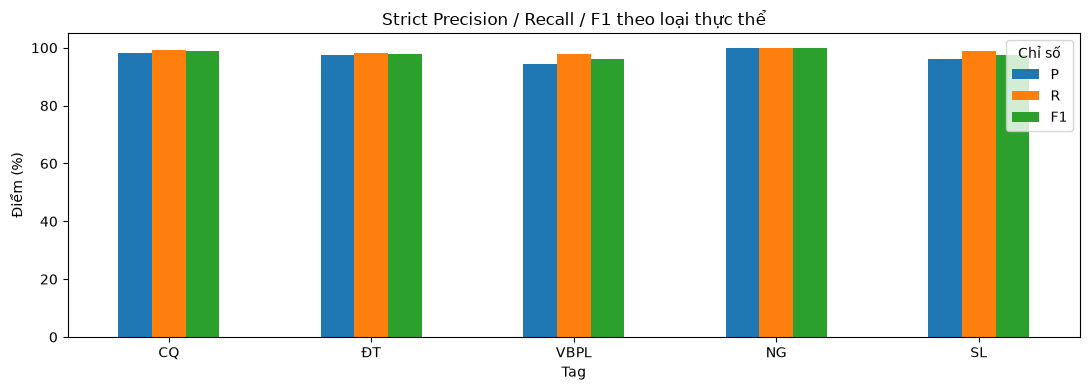

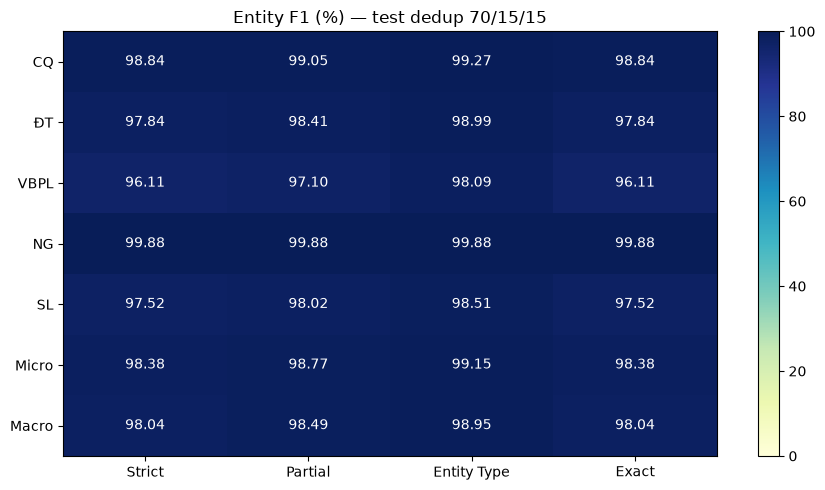

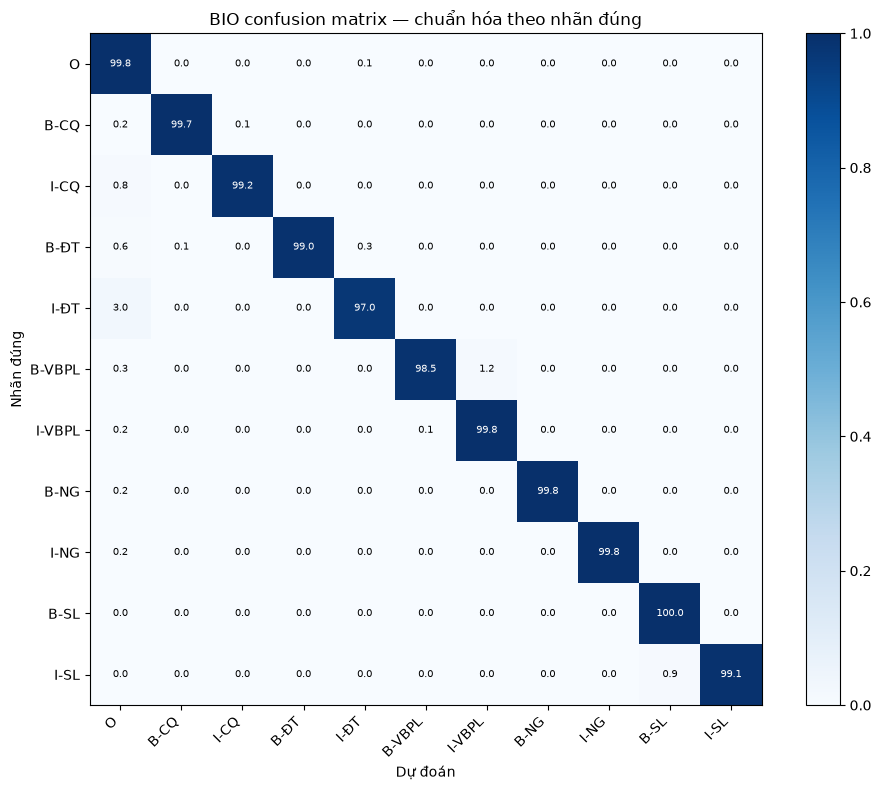

{
  "is_full_test": true,
  "evaluated_sentences": 5162,
  "evaluated_words": 117462,
  "coverage_pct": 100.0,
  "long_sentences": 0,
  "strict_entity_micro_f1_pct": 98.38152105593967,
  "strict_entity_macro_f1_pct": 98.03719849375202,
  "bio_token_accuracy_pct": 99.7139500434183
}


In [10]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(11, 4))
entity_strict = metric_table.loc[ENTITY_TAGS, "Strict"]
entity_strict.plot.bar(ax=ax, ylim=(0, 105), rot=0)
ax.set_ylabel("Điểm (%)")
ax.set_title("Strict Precision / Recall / F1 theo loại thực thể")
ax.legend(title="Chỉ số")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "strict_metrics_by_entity.png", dpi=180)
plt.show()
plt.close(fig)

heatmap_values = np.array([[metric_table.loc[tag, (title, "F1")] for _, title in SCENARIOS]
                          for tag in metric_table.index])
fig, ax = plt.subplots(figsize=(9, 5))
im = ax.imshow(heatmap_values, cmap="YlGnBu", vmin=0, vmax=100, aspect="auto")
ax.set_xticks(range(4), [title for _, title in SCENARIOS])
ax.set_yticks(range(len(metric_table)), metric_table.index)
for row in range(heatmap_values.shape[0]):
    for column in range(4):
        value = heatmap_values[row, column]
        ax.text(column, row, f"{value:.2f}", ha="center", va="center",
                color="white" if value > 65 else "black")
ax.set_title("Entity F1 (%) — test dedup 70/15/15")
fig.colorbar(im, ax=ax)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "entity_f1_heatmap.png", dpi=180)
plt.show()
plt.close(fig)

matrix = confusion_matrix(gold_flat, pred_flat, labels=classes)
normalized = np.divide(matrix, matrix.sum(axis=1, keepdims=True),
                       out=np.zeros_like(matrix, dtype=float), where=matrix.sum(axis=1, keepdims=True) != 0)
fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(normalized, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(classes)), classes, rotation=45, ha="right")
ax.set_yticks(range(len(classes)), classes)
ax.set_xlabel("Dự đoán")
ax.set_ylabel("Nhãn đúng")
ax.set_title("BIO confusion matrix — chuẩn hóa theo nhãn đúng")
for row in range(len(classes)):
    for column in range(len(classes)):
        ax.text(column, row, f"{100 * normalized[row, column]:.1f}", ha="center", va="center",
                fontsize=7, color="white" if normalized[row, column] > 0.5 else "black")
fig.colorbar(im, ax=ax)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "bio_confusion_matrix.png", dpi=180)
plt.show()
plt.close(fig)


def invalid_bio_count(tag_sequences):
    count = 0
    for sequence in tag_sequences:
        previous = "O"
        for tag in sequence:
            if tag.startswith("I-") and previous not in ("B-" + tag[2:], "I-" + tag[2:]):
                count += 1
            previous = tag
    return count


manifest = {
    "task": "inference_only_no_training", "source_repository": SOURCE_REPO,
    "source_commit": SOURCE_COMMIT, "release": "v1.0.0",
    "checkpoint_sha256": CHECKPOINT_SHA256, "model_id": MODEL_ID,
    "config_tokenizer_revision": MODEL_REVISION, "dataset": DATASET_ID,
    "dataset_revision": DATASET_REVISION, "test_filename": TEST_FILENAME,
    "test_sha256": sha256_file(test_path), "full_test_sentences": len(all_test_sentences),
    "evaluated_sentences": len(sentences), "evaluated_words": total_words,
    "is_full_test": len(sentences) == len(all_test_sentences), "coverage_pct": 100.0,
    "segments": len(segments), "long_sentences": len(long_rows),
    "long_sentence_policy": LONG_SENTENCE_POLICY, "max_seq_length": MAX_SEQ_LENGTH,
    "inference_batch_size": BATCH_SIZE, "encoder_amp": USE_AMP, "crf_precision": "float32",
    "gold_passed_to_model": False, "checkpoint_loaded_strictly": True,
    "gold_invalid_bio_transitions": invalid_bio_count(gold_sentences),
    "predicted_invalid_bio_transitions": invalid_bio_count(prediction_sentences),
    "device": str(DEVICE), "gpu_name": torch.cuda.get_device_name(DEVICE) if DEVICE.type == "cuda" else None,
    "peak_gpu_memory_mb": torch.cuda.max_memory_allocated(DEVICE) / 1024**2 if DEVICE.type == "cuda" else None,
    "inference_wall_seconds_excluding_tokenization_and_warmup": inference_seconds,
    "model_and_transfer_seconds": model_seconds,
    "amortized_ms_per_sentence": 1000 * inference_seconds / len(sentences),
    "sentences_per_second": len(sentences) / inference_seconds,
    "timing_note": "Batched inference; not single-request latency. Download/tokenization/warm-up excluded.",
    "strict_entity_micro_precision_pct": 100 * strict_micro.precision,
    "strict_entity_micro_recall_pct": 100 * strict_micro.recall,
    "strict_entity_micro_f1_pct": 100 * strict_micro.f1,
    "strict_entity_macro_f1_pct": float(metric_table.loc["Macro", ("Strict", "F1")]),
    "bio_token_accuracy_pct": 100 * float(tokens_df.correct.mean()),
    "seconds_since_notebook_config": time.perf_counter() - NOTEBOOK_START,
    "python": platform.python_version(),
    "libraries": {name: importlib.metadata.version(name) for name in (
        "torch", "transformers", "huggingface_hub", "pytorch-crf", "nervaluate",
        "numpy", "pandas", "scikit-learn", "matplotlib")},
}
(OUTPUT_DIR / "run_manifest.json").write_text(json.dumps(manifest, ensure_ascii=False, indent=2), encoding="utf-8")
print(json.dumps({key: manifest[key] for key in (
    "is_full_test", "evaluated_sentences", "evaluated_words", "coverage_pct", "long_sentences",
    "strict_entity_micro_f1_pct", "strict_entity_macro_f1_pct", "bio_token_accuracy_pct")},
    ensure_ascii=False, indent=2))


## Bước 10 — Tải kết quả

ZIP chứa dự đoán, lỗi token, bảng metrics, ảnh và manifest; **không nhúng lại
checkpoint 539 MB**. Checkpoint vẫn ở thư mục downloads nếu cần dùng lại.
Với Kaggle Save Version, chọn lưu outputs; tải ZIP trong Output hoặc nhấn link.

In [11]:
archive_path = ROOT / "papner_hsupcon_test_predictions.zip"
with zipfile.ZipFile(archive_path, "w", compression=zipfile.ZIP_DEFLATED) as archive:
    for path in sorted(OUTPUT_DIR.iterdir()):
        if path.is_file():
            archive.write(path, arcname=path.name)
print("KẾT QUẢ ĐÃ LƯU:")
for path in sorted(OUTPUT_DIR.iterdir()):
    print(f"  {path.name:42} {path.stat().st_size / 1024:10.1f} KiB")
print("\nZIP:", archive_path)
display(FileLink(str(archive_path)))


KẾT QUẢ ĐÃ LƯU:
  bio_confusion_matrix.png                        117.7 KiB
  bio_token_metrics.csv                             1.0 KiB
  checkpoint_training_config.json                   1.3 KiB
  entity_f1_heatmap.png                            81.3 KiB
  entity_metric_counts.csv                          1.8 KiB
  entity_metrics.csv                                1.6 KiB
  long_sentences.csv                                0.0 KiB
  run_manifest.json                                 2.2 KiB
  strict_metrics_by_entity.png                     32.7 KiB
  test_predictions.txt                           1938.8 KiB
  test_predictions_full.conll                    2672.7 KiB
  test_predictions_sentences.jsonl               2906.0 KiB
  test_predictions_tokens.csv                    3353.5 KiB
  token_errors.csv                                 11.8 KiB

ZIP: E:\Github\papner_hsupcon_inference\verification\papner_hsupcon_test_predictions.zip


E:\Github\papner_hsupcon_inference\verification\papner_hsupcon_test_predictions.zip